<div style="text-align: center;">
<h1>Comparing BattleActs’ Exam Preparation Samples</h1>
<h3>DATASCI 530 — Project 2</h3>
<p>Maxine Hakimi-Bulson</p>
</div>

## Introduction

BattleActs provides study materials for actuarial candidates preparing for Casualty Actuarial Society (CAS) exams. This project builds on my Project 1 collection of six exam preparation courses, nine public PDF samples, and six Excel workbooks collected on October 19, 2026.

The question this project aims to answer is: **How do BattleActs’ public samples differ across exams in their length, frequent terminology, and shared vocabulary?** I compare materials with the same purpose, keeping study manuals, formula summaries, and workbooks separate. The product information collected provides context for these comparisons.

### Key Findings

- Study-manual samples are available for all six exams, but their readable text lengths differ substantially.
- Frequent phrases distinguish the samples: examples include “increased limits” in Exam 5, “residual market” in Exam 6U, and “structured finance” in Exam 9.
- Exams 5 and 7 have the highest vocabulary overlap among the manual samples, sharing approximately 20.5% of their combined distinct cleaned words.
- Public sample availability differs by exam: formula summaries are available for three exams and workbooks for five. These differences describe the public samples, not the completeness or quality of the full courses.

In [1]:
from pathlib import Path
from collections import Counter
import csv
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pypdf import PdfReader
from openpyxl import load_workbook
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from IPython.display import display, HTML

# The notebook, CSVs, and sample_files folder share the same parent folder.
DATA_DIR = Path(".")
SAMPLE_DIR = DATA_DIR / "sample_files"
OUTPUT_DIR = DATA_DIR / "project2_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

products_final = pd.read_csv(DATA_DIR / "battleacts_products.csv")
pdf_samples = pd.read_csv(DATA_DIR / "battleacts_pdf_samples.csv")
excel_samples = pd.read_csv(DATA_DIR / "battleacts_excel_samples.csv")

exam_order = products_final["product_name"].tolist()

colors = [
    "#245B78", "#2A7F83", "#638A58",
    "#AE783B", "#76629A", "#AA5664"
]
exam_colors = dict(zip(exam_order, colors))

plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110
})

display(HTML("""
<style>
.report-table {
    border-collapse: collapse;
    margin: 16px auto;
    font-size: 14px;
}
.report-table th, .report-table td {
    padding: 9px 12px;
    text-align: center !important;
    border-bottom: 1px solid #dce3e7;
}
.report-table th {
    background-color: #245B78;
    color: white;
}
.report-table tbody tr:nth-child(even) {
    background-color: #f3f7f9;
}
.output_png img, .jp-OutputArea-output img {
    max-width: 100%;
    height: auto;
}
</style>
"""))

def show_table(frame, formats=None):
    display(HTML(frame.to_html(
        index=False,
        classes="report-table",
        border=0,
        na_rep="—",
        formatters=formats
    )))

## Data Sources and Project 1 Revisions

BattleActs granted written permission for the one-time educational collection. This project imports the saved Project 1 datasets and processes the previously downloaded sample files.

Project 1 feedback identified problems when the CSVs of the extracted text from the PDF and Excel file sample materials were opened in Excel. Some document text exceeded Excel’s limit of 32,767 characters per cell. For the CSV of the extracted text from the PDF sample materials (`battleacts_pdf_sample`), it appears that the content of the first listed exam was incorrectly parsed and filled many of the entries of the spreadsheet. It seems that the other exams were parsed correctly and have a clear format. The CSV containing extracted text from the Excel sample materials was more corrupted. I believe that CSV is not a sufficiently rich format to store this data, as it appears corrupted when the CSV is opened in Excel.

To address these issues, the analysis will look directly at the downloaded sample materials in their original PDF and Excel files rather than the CSV created in Project 1. PDF text is now organized by page and workbook text by worksheet. Spreadsheet formulas are counted separately and excluded from the language analysis. Numeric-only spreadsheet cells are also excluded because this analysis concerns written terminology rather than calculated answers. The exported text fields are checked for excessive length, and each CSV is examined and opened in Excel to confirm that its rows, columns, and text are preserved.

In [2]:
# Combine file metadata without using the old extracted_text columns.
metadata_columns = [
    "product_name", "sample_label", "sample_url", "product_url",
    "collection_date", "content_collection_date"
]

pdf_inventory = pdf_samples[
    metadata_columns + ["page_count"]
].copy()
pdf_inventory["file_type"] = "PDF"

excel_inventory = excel_samples[
    metadata_columns + ["sheet_count", "formula_cells"]
].copy()
excel_inventory["file_type"] = "Excel"

inventory = pd.concat(
    [pdf_inventory, excel_inventory],
    ignore_index=True
)

def identify_file(row):
    label = row["sample_label"].lower()

    if row["file_type"] == "PDF":
        if "study manual" in label:
            return "Study manual", "Study_manual.pdf"
        return "Formula summary", "Formula_summary_sheet.pdf"

    if "past cas exams" in label:
        return "Workbook", "Past_CAS_exams.xlsx"

    return "Workbook", "Practice_problems_and_exams.xlsx"

file_details = inventory.apply(identify_file, axis=1)
inventory["material"] = file_details.map(lambda value: value[0])
inventory["filename"] = file_details.map(lambda value: value[1])

inventory["exam_folder"] = inventory["product_name"].str.replace(
    r"[^A-Za-z0-9]+", "_", regex=True
).str.strip("_")

inventory["local_path"] = inventory.apply(
    lambda row: (
        SAMPLE_DIR
        / row["file_type"]
        / row["exam_folder"]
        / row["filename"]
    ),
    axis=1
)

missing_files = [
    str(path) for path in inventory["local_path"]
    if not path.is_file()
]

if missing_files:
    raise FileNotFoundError(
        "Check these sample file locations:\n" + "\n".join(missing_files)
    )

# Confirm that file records are unique and linked to known products.
assert products_final["product_url"].is_unique
assert inventory["sample_url"].is_unique
assert inventory["product_url"].isin(
    products_final["product_url"]
).all()

## Extracting Readable Sample Content

Each PDF page and Excel worksheet becomes a separate record linked to its exam and source URL. Page counts, worksheet counts, and formula counts are compared with the Project 1 metadata.

Workbook cells containing formulas are excluded from the extracted narrative text. Text from instruction sheets, contents sheets, and score grids is retained in the exported data but excluded from vocabulary comparisons. The remaining worksheets are used for analysis.

This approach preserves the original files for reference while producing smaller text records that are easier to inspect and analyze.

In [3]:
admin_sheets = {
    "instructions", "point grid", "toc",
    "contents", "table of contents"
}

source_columns = [
    "product_name", "sample_url", "product_url",
    "collection_date", "content_collection_date",
    "file_type", "material"
]

records = []

for _, file in inventory.iterrows():
    common = {column: file[column] for column in source_columns}

    if file["file_type"] == "PDF":
        reader = PdfReader(file["local_path"])

        assert len(reader.pages) == int(file["page_count"])

        for page_number, page in enumerate(reader.pages, start=1):
            records.append({
                **common,
                "unit": str(page_number),
                "included": True,
                "formula_cells": 0,
                "raw_text": page.extract_text() or ""
            })

    else:
        book = load_workbook(
            file["local_path"],
            read_only=True,
            data_only=False
        )

        try:
            assert len(book.sheetnames) == int(file["sheet_count"])
            total_formulas = 0

            for sheet in book.worksheets:
                blocks = []
                formulas = 0

                for row in sheet.iter_rows():
                    for cell in row:
                        if cell.data_type == "f":
                            formulas += 1

                        elif (
                            isinstance(cell.value, str)
                            and re.search(r"[A-Za-z]", cell.value)
                        ):
                            blocks.append(cell.value.strip())

                total_formulas += formulas

                records.append({
                    **common,
                    "unit": sheet.title,
                    "included": (
                        sheet.title.strip().lower() not in admin_sheets
                    ),
                    "formula_cells": formulas,
                    "raw_text": "\n".join(blocks)
                })

            assert total_formulas == int(file["formula_cells"])

        finally:
            book.close()

segments = pd.DataFrame(records)

# Check that every expected page and worksheet was processed.
assert segments["sample_url"].nunique() == len(inventory)

assert segments["file_type"].eq("PDF").sum() == int(
    pdf_samples["page_count"].sum()
)

assert segments["file_type"].eq("Excel").sum() == int(
    excel_samples["sheet_count"].sum()
)

assert not segments.duplicated(["sample_url", "unit"]).any()

assert not segments["raw_text"].str.contains(
    "object at 0x", regex=False
).any()

## Preparing Text for Comparison

The original extraction is retained, and a separate version is cleaned for analysis. Lines containing website addresses, navigation links, or identifiable PDF footer text are removed. Common English stopwords and recurring document labels are excluded from vocabulary summaries. Two-word phrases are counted only when the words were adjacent within the same text line and sentence. Counts are case-insensitive, and singular and plural forms remain separate. These are exact vocabulary comparisons rather than automated classifications of topics from the CAS syllabus.

In [4]:
noise = re.compile(
    r"https?://|www\.|battleacts\d*\.ca|retrieved from|last edited"
    r"|return to (?:toc|point grid)|mini battlequiz|full battlequiz"
    r"|must be logged in|click for answer|^\s*\d+/\d+\s*$",
    re.I
)

def clean_text(text):
    lines = []

    for line in text.splitlines():
        if not noise.search(line):
            lines.append(re.sub(r"\s+", " ", line).strip())

    return "\n".join(line for line in lines if line)

segments["analysis_text"] = segments["raw_text"].map(clean_text)

document_labels = set("""
battleacts battlequiz battlecards wiki pdf worksheet
question questions answer answers problem problems
example examples calculate calculation following given
reading synopsis study tips plain english contents
return point grid points available achieved incomplete
complete werner sneak peek article sample
""".split())

stopwords = set(ENGLISH_STOP_WORDS) | document_labels

# Exclude generic phrases and repeated-word pairs from phrase summaries.
excluded_phrases = {"web based", "source text"}

def tokens(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())

def useful_word(word):
    return len(word) >= 3 and word not in stopwords

def count_terms(text):
    word_counts = Counter()
    phrase_counts = Counter()
    total_words = 0

    for line in text.splitlines():
        for sentence in re.split(r"[.!?;]", line):
            sequence = tokens(sentence)
            total_words += len(sequence)

            word_counts.update(
                word for word in sequence if useful_word(word)
            )

            for first, second in zip(sequence, sequence[1:]):
                phrase = first + " " + second

                if (
                    useful_word(first)
                    and useful_word(second)
                    and first != second
                    and phrase not in excluded_phrases
                ):
                    phrase_counts[phrase] += 1

    return total_words, word_counts, phrase_counts

segments["word_count"] = segments["analysis_text"].map(
    lambda text: len(tokens(text))
)

### Comparing Samples of Different Lengths

Text is grouped by exam and material category. Word counts describe the cleaned readable text before stopword removal. Frequent phrases are reported as occurrences per 1,000 words so that longer samples do not automatically receive higher frequencies. A missing material category is treated as unavailable rather than as a document containing zero words.

In [5]:
analysis_segments = segments[segments["included"]].copy()

stats = {}

for (exam, material), group in analysis_segments.groupby(
    ["product_name", "material"],
    sort=False
):
    text = "\n".join(group["analysis_text"])
    total_words, word_counts, phrase_counts = count_terms(text)

    stats[(exam, material)] = {
        "word_count": total_words,
        "words": word_counts,
        "phrases": phrase_counts
    }

# Confirm that each exam has usable manual text.
assert all(
    stats[(exam, "Study manual")]["word_count"] > 0
    for exam in exam_order
)

## Results

### Table 1. Courses and Public Sample Availability

The table summarizes all six courses and the unique PDF and Excel files collected for each. Prices retain their listed currency. Sample counts refer to files, while original practice-exam counts describe the advertised course offering.

In [6]:
overview = products_final[[
    "product_name", "price", "currency",
    "duration_months", "practice_exam_count"
]].copy()

overview["Listed price"] = overview.apply(
    lambda row: f'{row["price"]:,.0f} {row["currency"]}',
    axis=1
)

overview["PDF files"] = overview["product_name"].map(
    inventory[inventory["file_type"].eq("PDF")]
    .groupby("product_name").size()
).fillna(0).astype(int)

overview["Excel files"] = overview["product_name"].map(
    inventory[inventory["file_type"].eq("Excel")]
    .groupby("product_name").size()
).fillna(0).astype(int)

overview = overview.rename(columns={
    "product_name": "Exam prep course",
    "duration_months": "Access (months)",
    "practice_exam_count": "Advertised original practice exams"
})

overview = overview[[
    "Exam prep course", "Listed price", "Access (months)",
    "Advertised original practice exams", "PDF files", "Excel files"
]]

show_table(overview)

Exam prep course,Listed price,Access (months),Advertised original practice exams,PDF files,Excel files
CAS Exam 5,500 USD,7,4,2,1
CAS Exam 6C,"1,000 CAD",7,1,1,1
CAS Exam 6U,"1,000 USD",7,2,2,2
CAS Exam 7,"1,000 USD",7,2,2,1
CAS Exam 8,"1,000 USD",7,2,1,1
CAS Exam 9,"1,000 USD",7,2,1,0


Five courses are priced in USD, with a mean listed price of $900 and a sample variance of 50,000 USD². Exam 6C is priced separately at CAD 1,000; its price variance cannot be calculated from one observation. All courses advertise seven months of access and a conditional six-month extension.

All six exams provide a manual sample. Formula-summary PDFs are available for Exams 5, 6U, and 7, and workbook samples are available for every exam except Exam 9. Two Exam 5 sample buttons linked to the same PDF, which is counted once.

### Table 2. Readable Text Available for Analysis

Word counts are calculated after removing identifiable navigation and footer text, but before excluding stopwords. Workbook counts exclude administrative worksheets and formula cells. A dash indicates that no sample of that type was available.

In [7]:
rows = []

for exam in exam_order:
    row = {"Exam": exam}

    for material, column in [
        ("Study manual", "Manual words"),
        ("Formula summary", "Formula-summary words"),
        ("Workbook", "Workbook words")
    ]:
        result = stats.get((exam, material))
        row[column] = (
            result["word_count"] if result is not None else np.nan
        )

    workbook_units = analysis_segments[
        analysis_segments["product_name"].eq(exam)
        & analysis_segments["file_type"].eq("Excel")
    ]

    row["Worksheets analyzed"] = (
        len(workbook_units) if len(workbook_units) else np.nan
    )

    rows.append(row)

text_summary = pd.DataFrame(rows)

show_table(
    text_summary,
    {
        column: "{:,.0f}".format
        for column in text_summary.columns
        if column != "Exam"
    }
)

Exam,Manual words,Formula-summary words,Workbook words,Worksheets analyzed
CAS Exam 5,"6,530",711,"2,441",30
CAS Exam 6C,"3,252",—,"2,250",10
CAS Exam 6U,"2,090",715,"2,958",29
CAS Exam 7,"3,604","1,054",919,3
CAS Exam 8,"2,903",—,"4,088",15
CAS Exam 9,"4,029",—,—,—


The manual samples range from approximately 2,100 to 6,500 readable words. Exam 5 has the longest manual sample, while Exam 6U has the shortest. This variation supports comparing normalized frequencies rather than raw counts alone. Exam 9 has a public study-manual PDF but no formula-summary PDF or downloadable Excel workbook in this collection. The dashes indicate unavailable samples, rather than missing text from an existing file.

Across the six workbooks, 95 worksheets were extracted and 87 remained after excluding administrative tabs. Worksheet totals are not question totals: a worksheet can contain several questions, subparts, explanatory text, or solutions.

Formula summaries also differ in length and layout. Their text counts describe extracted terminology and should not be interpreted as counts of mathematical formulas.

### Figure 1. Frequent Phrases in Study-Manual Samples

Each panel shows the five most frequent eligible two-word phrases in one manual sample. All panels use the same horizontal scale, measured in occurrences per 1,000 words.

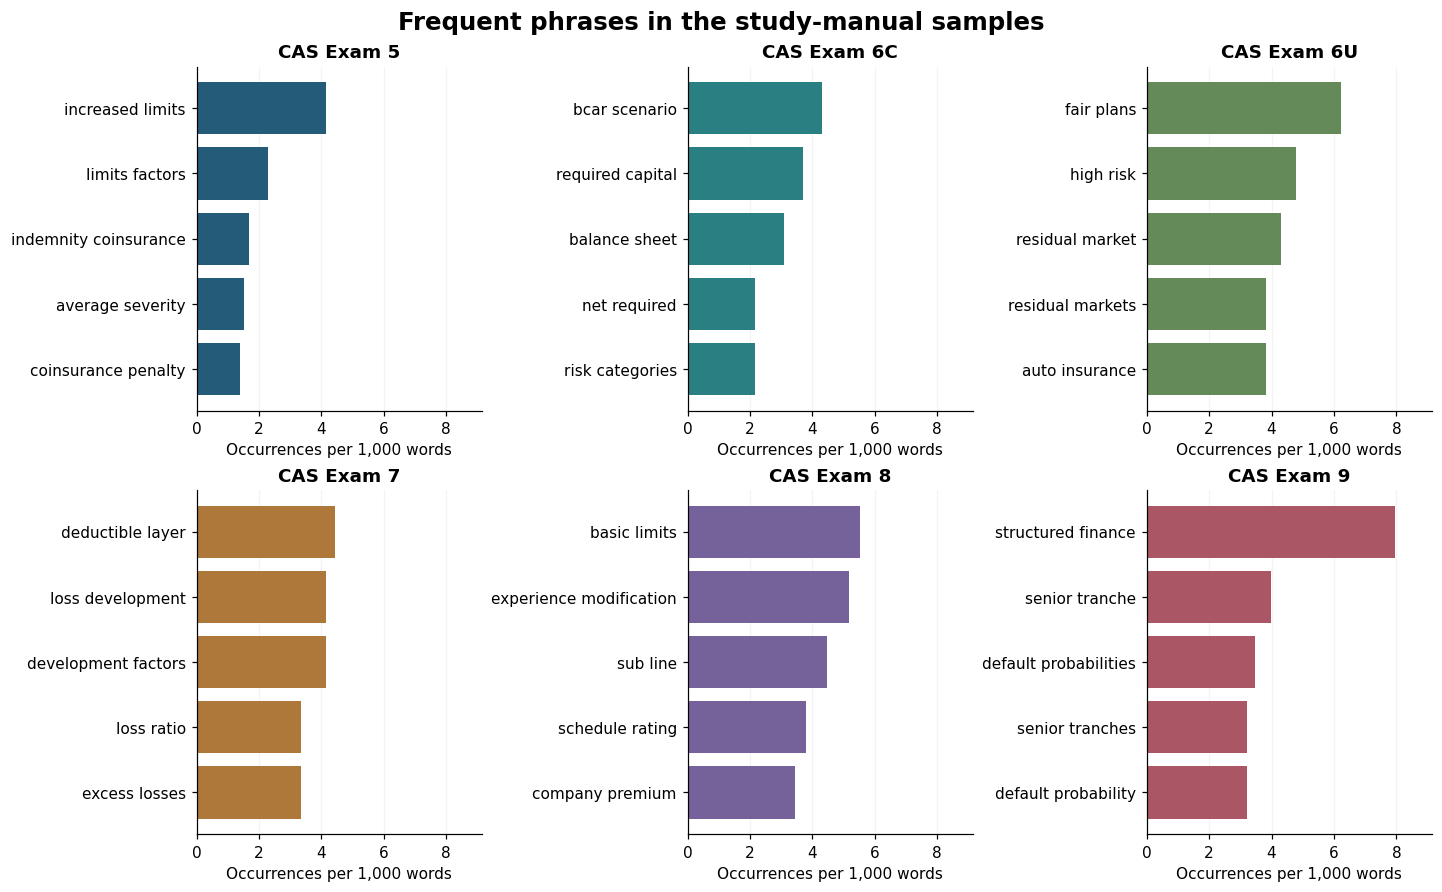

In [8]:
def phrase_panels(material, title):
    available = [
        exam for exam in exam_order
        if (exam, material) in stats
    ]

    fig, axes = plt.subplots(
        2, 3,
        figsize=(13, 8),
        layout="constrained"
    )

    for ax in axes.flat:
        ax.set_visible(False)

    maximum = max(
        (
            1000 * count / stats[(exam, material)]["word_count"]
            for exam in available
            for phrase, count in
            stats[(exam, material)]["phrases"].most_common(5)
        ),
        default=1
    )

    for ax, exam in zip(axes.flat, available):
        ax.set_visible(True)

        result = stats[(exam, material)]
        top = result["phrases"].most_common(5)

        phrases = [phrase for phrase, count in top]
        frequencies = [
            1000 * count / result["word_count"]
            for phrase, count in top
        ]

        ax.barh(
            phrases,
            frequencies,
            color=exam_colors[exam]
        )

        ax.invert_yaxis()
        ax.set_xlim(0, maximum * 1.15)
        ax.set_title(exam, fontweight="bold")
        ax.set_xlabel("Occurrences per 1,000 words")
        ax.grid(axis="x", alpha=0.15)
        ax.set_axisbelow(True)

    fig.suptitle(title, fontsize=16, fontweight="bold")
    plt.show()

phrase_panels(
    "Study manual",
    "Frequent phrases in the study-manual samples"
)

The leading phrases distinguish the subject matter of the selected manual excerpts. Exam 5 frequently mentions increased limits and coinsurance, Exam 6C discusses capital and BCAR scenarios, and Exam 6U emphasizes residual markets and high-risk insurance. Exam 7 includes loss-development terminology, Exam 8 emphasizes experience modification and rating, and Exam 9 focuses on structured finance and tranches.

These patterns suggest that the samples provide different subject-specific previews. They do not show how much of each topic is covered in the complete course.

### Figure 2. Shared Vocabulary Between Manual Samples

Jaccard similarity measures the proportion of distinct cleaned words shared by two samples out of all distinct words appearing in either. A value of 20% means that one-fifth of their combined vocabulary appears in both samples.

The calculation uses words of at least three letters after stopword and document-label removal. It compares terminology rather than meaning, difficulty, or syllabus coverage.

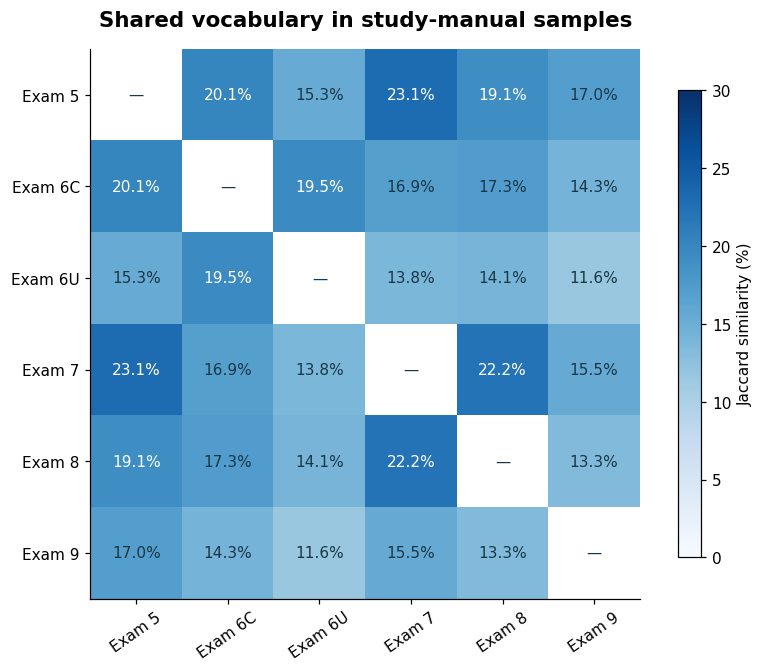

In [9]:
manual_vocabulary = {
    exam: set(stats[(exam, "Study manual")]["words"])
    for exam in exam_order
}

similarity = pd.DataFrame(
    index=exam_order,
    columns=exam_order,
    dtype=float
)

for first in exam_order:
    for second in exam_order:
        shared = (
            manual_vocabulary[first]
            & manual_vocabulary[second]
        )
        combined = (
            manual_vocabulary[first]
            | manual_vocabulary[second]
        )

        similarity.loc[first, second] = (
            100 * len(shared) / len(combined)
            if combined else np.nan
        )

# Omit self-comparisons from the figure.
heatmap_values = similarity.to_numpy().copy()
np.fill_diagonal(heatmap_values, np.nan)

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")

image = ax.imshow(
    np.ma.masked_invalid(heatmap_values),
    cmap="Blues",
    vmin=0,
    vmax=30
)

short_labels = [
    exam.replace("CAS ", "") for exam in exam_order
]

ax.set_xticks(range(len(exam_order)), short_labels, rotation=35)
ax.set_yticks(range(len(exam_order)), short_labels)

for row in range(len(exam_order)):
    for column in range(len(exam_order)):
        value = heatmap_values[row, column]

        ax.text(
            column,
            row,
            "—" if np.isnan(value) else f"{value:.1f}%",
            ha="center",
            va="center",
            color="white" if value > 18 else "#193746"
        )

ax.set_title(
    "Shared vocabulary in study-manual samples",
    fontsize=14,
    fontweight="bold",
    pad=15
)

colorbar = fig.colorbar(image, ax=ax, shrink=0.85)
colorbar.set_label("Jaccard similarity (%)")

plt.show()

Exams 5 and 7 have the highest manual vocabulary similarity, at approximately 20.5%, followed by Exams 7 and 8 at approximately 19.1%. This is consistent with shared terminology involving losses, development, and insurance calculations, although the excerpts address different subjects.

The percentages are sensitive to sample length, chapter selection, and cleaning rules. Low overlap does not imply that courses are unrelated, and high overlap does not establish that they teach the same material.

### Figure 3. Frequent Phrases in Workbook Samples

The workbook comparison uses readable text from the non-administrative worksheets. Formula expressions and numeric-only cells are excluded. The two Exam 6U workbooks are combined for this exam-level summary.

Exam 9 is absent because no public workbook was available in the collection.

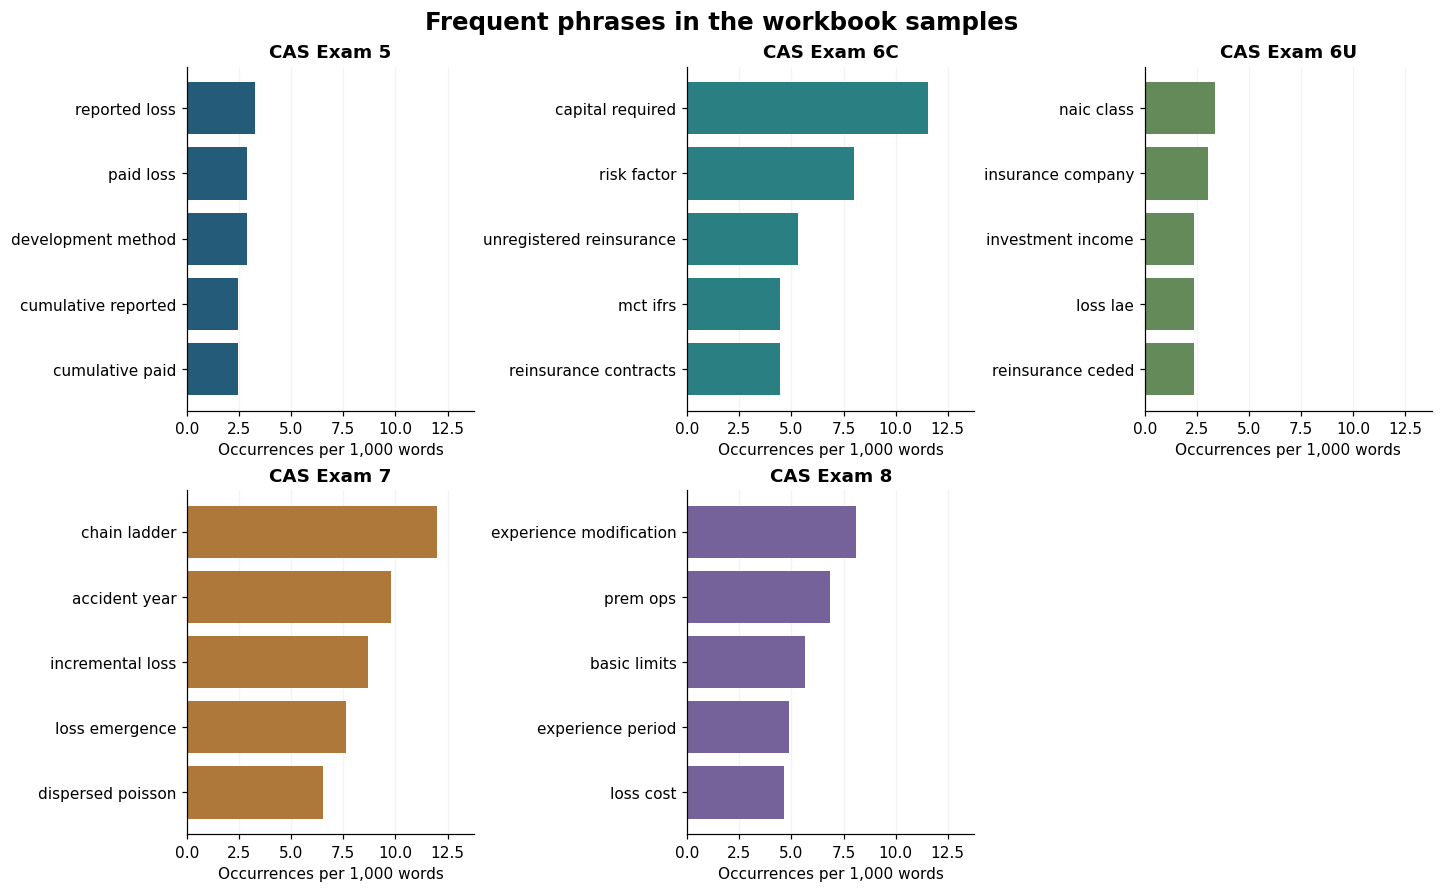

In [10]:
phrase_panels(
    "Workbook",
    "Frequent phrases in the workbook samples"
)

Workbook phrases provide a second view of the available material. Exam 5 includes reported and paid losses and development methods. Exam 6C frequently refers to capital requirements and risk factors, while Exam 7 includes chain-ladder and loss-emergence terminology. Exam 8 repeatedly mentions experience modification and basic limits.

Some terminology appears in both the manual and workbook samples for the same exam. For example, experience modification appears prominently in both Exam 8 comparisons. This provides evidence of a connection between the selected explanatory material and practice content, without demonstrating complete topic coverage.

Exam 6U combines two workbooks with different purposes and sizes. Its phrase distribution therefore reflects the pooled public examples rather than an equal contribution from each workbook.

## Discussion

The public samples provide distinct previews of the six courses. Differences in frequent phrases are more informative than file counts alone because they reveal the terminology students can encounter before purchasing access.

For BattleActs, these results could help describe the focus of each public sample more clearly. The shared Exam 5 PDF destination under differently labeled buttons is also worth reviewing, since a button referring to Excel leads to a PDF. Sample availability could be communicated explicitly so visitors can distinguish unavailable previews from materials included in the paid course.

The analysis has several limitations. Public samples are selected excerpts rather than representative samples of complete courses. PDF extraction can disrupt tables and mathematical notation, while workbook text includes labels, explanations, and solutions alongside prompts. Phrase counts do not measure understanding, difficulty, teaching quality, or student outcomes. Exact-word similarity also treats singular and plural forms separately.

A future extension could classify clearly identifiable practice questions or compare samples with official exam topics. That would require additional validation and subject-matter knowledge beyond the descriptive vocabulary comparisons presented here.

## Revised Datasets and Reproducibility

Three CSVs are exported: the product dataset, PDF text organized by page, and Excel text organized by worksheet. Original source URLs and collection timestamps are retained.

The text datasets contain readable extracted content rather than reconstructed PDF tables or functioning spreadsheets. Original sample files remain the reference for layout, calculations, and mathematical notation.

Whitespace is standardized for export, every text field is checked against a conservative 30,000-character limit, and each saved CSV is reopened to verify that its contents are unchanged. These checks improve spreadsheet compatibility without discarding text to fit a cell.

In [11]:
# Build page-level PDF records.
pdf_samples_clean = segments[
    segments["file_type"].eq("PDF")
].copy()

pdf_samples_clean["page_number"] = (
    pdf_samples_clean["unit"].astype(int)
)

pdf_samples_clean = pdf_samples_clean.rename(columns={
    "raw_text": "extracted_text"
})

pdf_samples_clean = pdf_samples_clean[[
    "product_name", "material", "sample_url", "product_url",
    "collection_date", "content_collection_date",
    "page_number", "extracted_text", "word_count"
]]

# Build worksheet-level Excel records.
excel_samples_clean = segments[
    segments["file_type"].eq("Excel")
].copy()

excel_samples_clean = excel_samples_clean.rename(columns={
    "unit": "worksheet",
    "included": "included_in_analysis",
    "raw_text": "extracted_text"
})

excel_samples_clean = excel_samples_clean[[
    "product_name", "sample_url", "product_url",
    "collection_date", "content_collection_date",
    "worksheet", "included_in_analysis",
    "formula_cells", "extracted_text", "word_count"
]]

# Standardize whitespace without shortening or truncating the text.
for frame in [pdf_samples_clean, excel_samples_clean]:
    frame["extracted_text"] = (
        frame["extracted_text"]
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    assert frame["extracted_text"].str.len().le(30000).all(), (
        "An oversized text record needs to be split before export."
    )

exports = {
    "battleacts_products.csv": products_final,
    "battleacts_pdf_samples.csv": pdf_samples_clean,
    "battleacts_excel_samples.csv": excel_samples_clean
}

for filename, frame in exports.items():
    path = OUTPUT_DIR / filename

    frame.to_csv(
        path,
        index=False,
        encoding="utf-8-sig",
        quoting=csv.QUOTE_ALL
    )

    restored = pd.read_csv(path, keep_default_na=False)

    assert restored.shape == frame.shape
    assert restored.columns.tolist() == frame.columns.tolist()

    # Check all text columns, including URLs and timestamps.
    for column in frame.select_dtypes(include="object").columns:
        assert (
            restored[column].astype(str).tolist()
            == frame[column].fillna("").astype(str).tolist()
        )

## Source

BattleActs. Public product pages and linked PDF and Excel samples, collected October 19, 2026, with written permission for educational use.

Website: [BattleActs](https://battleactsmain.ca/v2/home)

All findings describe the materials available at the time of collection.